Procesando cosecha: 202507
Procesando cosecha: 202508
Procesando cosecha: 202509
Procesando cosecha: 202510
Procesando cosecha: 202511
Procesando cosecha: 202512
Procesando cosecha: 202601
Procesando cosecha: 202602

 Se eliminaron 5 variables por baja variabilidad (< 0.3 CV o casi constantes):
 - frec_components_prom_1m: CV: 0.0000
 - frec_components_prom_2m: CV: 0.0000
 - frec_components_prom_3m: CV: 0.0000
 - frec_components_prom_6m: CV: 0.0000
 - edad: CV: 0.1976

 Se eliminaron 16 variables por alta correlación (> 0.50) conservando la mejor frente al target:
 - frec_prom_3m
 - frec_prom_1m
 - frec_clothing_prom_2m
 - frec_accessories_prom_3m
 - frec_bikes_prom_6m
 - frec_accessories_prom_1m
 - frec_prom_2m
 - frec_bikes_prom_1m
 - monto_prom_3m
 - frec_prom_6m
 - frec_clothing_prom_1m
 - monto_prom_1m
 - frec_bikes_prom_3m
 - monto_prom_2m
 - frec_accessories_prom_2m
 - frec_clothing_prom_3m

 ¡Proceso completado! El tablón pasó de 44 columnas a 23 columnas.
 Variables descartadas

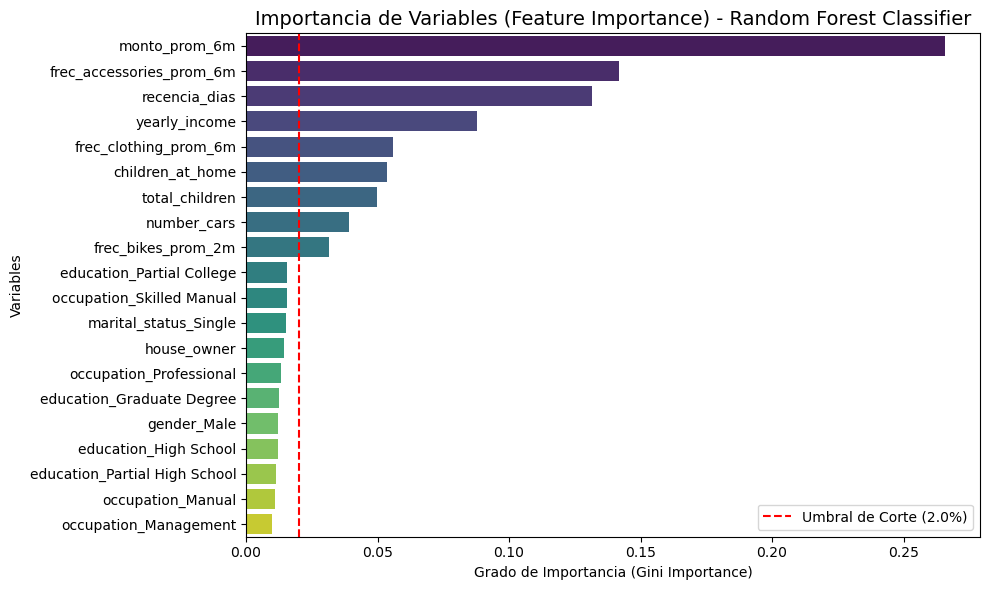

Evaluando Regresión Logística + Under...
Evaluando Random Forest + Under...
Evaluando XGBoost + Under...
Evaluando LightGBM + Under...

 === RESULTADOS 1: VALIDACIÓN CRUZADA EN TRAIN (ESTABILIDAD) ===


,Modelo,Accuracy (Train CV),Precision (Train CV),Recall (Train CV),F1-Score (Train CV)
0,Regresión Logística + Under,61.67%,35.02%,58.01%,43.67%
1,Random Forest + Under,72.65%,47.72%,70.57%,56.93%
2,XGBoost + Under,73.30%,48.61%,73.88%,58.62%
3,LightGBM + Under,73.36%,48.70%,74.54%,58.89%



 === RESULTADOS 2: EVALUACIÓN EN TEST OUT-OF-TIME (DEGRADACIÓN) ===


,Modelo,Accuracy (Test OOT),Precision (Test OOT),Recall (Test OOT),F1-Score (Test OOT)
0,Regresión Logística + Under,56.38%,20.86%,51.40%,29.68%
1,Random Forest + Under,79.71%,43.99%,48.80%,46.27%
2,XGBoost + Under,78.60%,42.61%,56.19%,48.47%
3,LightGBM + Under,80.09%,45.44%,55.92%,50.14%


Iniciando la optimización de hiperparámetros para LightGBM...
Fitting 5 folds for each of 81 candidates, totalling 405 fits

 Mejores parámetros LightGBM: {'lgb__colsample_bytree': 1.0, 'lgb__max_depth': 7, 'lgb__num_leaves': 31, 'lgb__subsample': 0.7}
Mejor F1-Score promedio en Train CV: 63.10%


,Métrica,Resultado LightGBM Optimizado (Test)
0,Accuracy,81.64%
1,Precision,49.04%
2,Recall,64.54%
3,F1-Score,55.73%


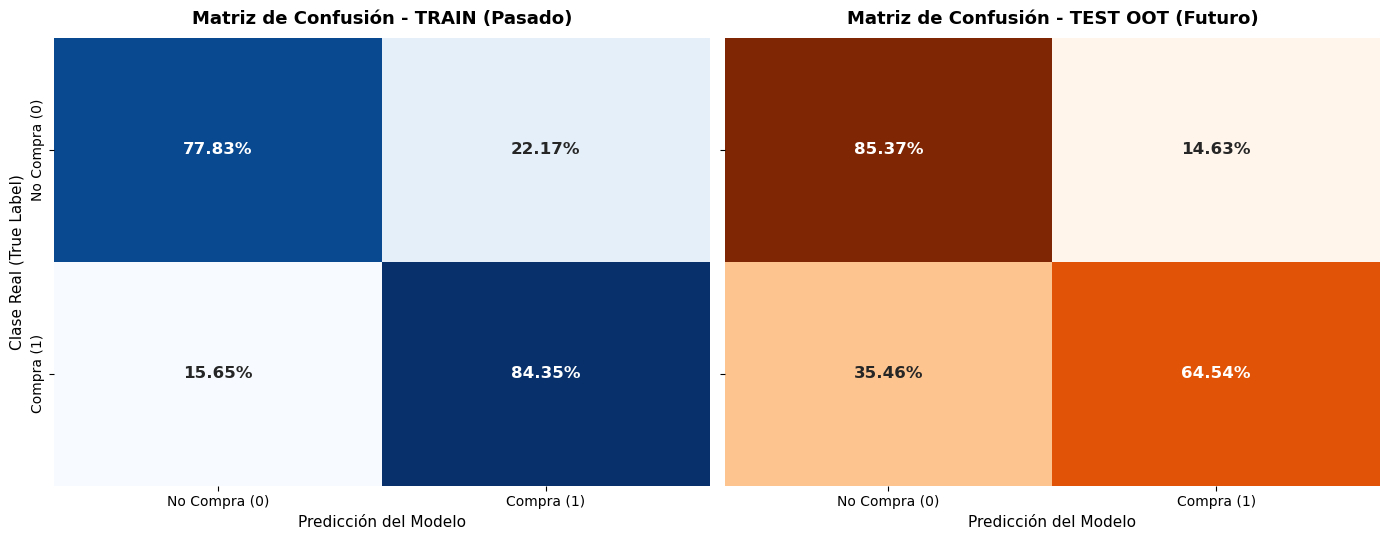

 REPORT DE CLASIFICACIÓN: DATASET DE TRAIN (PASADO)
               precision    recall  f1-score   support

No Compra (0)     0.9352    0.7783    0.8496     19237
   Compra (1)     0.5671    0.8435    0.6782      6625

     accuracy                         0.7950     25862
    macro avg     0.7512    0.8109    0.7639     25862
 weighted avg     0.8409    0.7950    0.8057     25862


 REPORTE DE CLASIFICACIÓN: DATASET DE TEST OOT (FUTURO)
               precision    recall  f1-score   support

No Compra (0)     0.9169    0.8537    0.8842      6699
   Compra (1)     0.4904    0.6454    0.5573      1461

     accuracy                         0.8164      8160
    macro avg     0.7037    0.7496    0.7208      8160
 weighted avg     0.8406    0.8164    0.8257      8160



In [3]:
# Databricks notebook source
# MAGIC %md
# MAGIC # 1. FUNCIONES UTILITARIAS

# COMMAND ----------

import datetime as dt
import numpy as np
import pandas as pd
from dateutil.relativedelta import relativedelta


# =============================================================================
# 1. FUNCIONES UTILITARIAS Y AJUSTE DE COSECHAS
# =============================================================================
def shift_codmes(codmes: int, n_months: int) -> int:
    year = codmes // 100
    month = codmes % 100
    date = dt.date(year, month, 1)
    new_date = date + relativedelta(months=n_months)
    return new_date.year * 100 + new_date.month


def function_listas_periodos(codmes_actual, n):
    lista_periodos = []
    for i in range(n):
        lista_periodos.append(shift_codmes(codmes_actual, -i))
    return lista_periodos


# =============================================================================
# 2. PIPELINE PRINCIPAL PARA CONSTRUIR EL TABLÓN ANALÍTICO (CORREGIDO)
# =============================================================================
def construir_tablon_analitico(df_sales, df_customers, df_productos, cosechas):
    """Genera el tablón de entrenamiento usando una estrategia de cosechas móviles

    calculando montos, frecuencias generales y conteos por categoría de producto.
    """
    # Clonamos para proteger los datos originales de la sesión
    df_sales_cp = df_sales.copy()

    # Preparación previa de Sales
    df_sales_cp["timestamp"] = pd.to_datetime(df_sales_cp["timestamp"])
    df_sales_cp["codmes"] = (
        df_sales_cp["timestamp"].dt.year * 100
        + df_sales_cp["timestamp"].dt.month
    )

    # Añadir categoría de producto a las ventas para variables de preferencia
    df_sales_prod = df_sales_cp.merge(
        df_productos[["product_id", "category"]], on="product_id", how="left"
    )

    # Limpieza estándar de los nombres de categorías para evitar problemas de strings
    df_sales_prod["category"] = (
        df_sales_prod["category"].fillna("Unknown").str.lower().str.strip()
    )

    # --- INGENIERÍA: CASE WHEN PARA CONTEO DE CATEGORÍAS ---
    df_sales_prod["frec_bikes"] = np.where(
        df_sales_prod["category"] == "bikes", 1, 0
    )
    df_sales_prod["frec_components"] = np.where(
        df_sales_prod["category"] == "components", 1, 0
    )
    df_sales_prod["frec_clothing"] = np.where(
        df_sales_prod["category"] == "clothing", 1, 0
    )
    df_sales_prod["frec_accessories"] = np.where(
        df_sales_prod["category"] == "accessories", 1, 0
    )

    # Agrupación mensual base por cliente incluyendo las frecuencias por categoría
    df_mensual_base = (
        df_sales_prod.groupby(["customer_id", "codmes"])
        .agg(
            monto_mes=("sales_amount", "sum"),
            frecuencia_mes=("sale_id", "nunique"),
            frec_bikes_mes=("frec_bikes", "sum"),
            frec_components_mes=("frec_components", "sum"),
            frec_clothing_mes=("frec_clothing", "sum"),
            frec_accessories_mes=("frec_accessories", "sum"),
        )
        .reset_index()
    )

    tablon_final = []

    for periodo in cosechas:
        print(f"Procesando cosecha: {periodo}")

        # --- A. DEFINICIÓN DE VENTANAS ---
        periodos_1m = function_listas_periodos(periodo, 1)
        periodos_2m = function_listas_periodos(periodo, 2)
        periodos_3m = function_listas_periodos(periodo, 3)
        periodos_6m = function_listas_periodos(periodo, 6)

        periodos_target = [shift_codmes(periodo, i) for i in range(1, 7)]

        # --- B. POBLACIÓN OBJETIVO DE LA COSECHA ---
        clientes_activos = df_mensual_base[
            df_mensual_base["codmes"].isin(periodos_6m)
        ]["customer_id"].unique()
        if len(clientes_activos) == 0:
            continue

        base_cosecha = pd.DataFrame({"customer_id": clientes_activos})
        base_cosecha["periodo_analisis"] = periodo

        # --- C. CONSTRUCCIÓN DEL TARGET ---
        compras_futuras = df_mensual_base[
            (df_mensual_base["codmes"].isin(periodos_target))
            & (df_mensual_base["monto_mes"] > 0)
        ]["customer_id"].unique()

        base_cosecha["target"] = np.where(
            base_cosecha["customer_id"].isin(compras_futuras), 1, 0
        )

        # --- D. EXTRACCIÓN DE VARIABLES AUTORREGRESIVAS COMPLETA ---
        # Ahora el bucle calcula promedios tanto de dinero/transacciones como de categorías compradas
        for n_meses, lista_p in zip([1,2,3,6], [periodos_1m, periodos_2m, periodos_3m, periodos_6m]
        ):
            df_filt = df_mensual_base[df_mensual_base["codmes"].isin(lista_p)]
            df_agrup = (
                df_filt.groupby("customer_id")
                .agg(
                    sum_monto=("monto_mes", "sum"),
                    sum_frec=("frecuencia_mes", "sum"),
                    sum_bikes=("frec_bikes_mes", "sum"),
                    sum_components=("frec_components_mes", "sum"),
                    sum_clothing=("frec_clothing_mes", "sum"),
                    sum_accessories=("frec_accessories_mes", "sum"),
                )
                .reset_index()
            )

            # Promedios fijos de montos y frecuencias generales
            df_agrup[f"monto_prom_{n_meses}m"] = df_agrup["sum_monto"] / n_meses
            df_agrup[f"frec_prom_{n_meses}m"] = df_agrup["sum_frec"] / n_meses

            # Promedios fijos del mix de categorías compradas por el cliente
            df_agrup[f"frec_bikes_prom_{n_meses}m"] = (
                df_agrup["sum_bikes"] / n_meses
            )
            df_agrup[f"frec_components_prom_{n_meses}m"] = (
                df_agrup["sum_components"] / n_meses
            )
            df_agrup[f"frec_clothing_prom_{n_meses}m"] = (
                df_agrup["sum_clothing"] / n_meses
            )
            df_agrup[f"frec_accessories_prom_{n_meses}m"] = (
                df_agrup["sum_accessories"] / n_meses
            )

            # Columnas seleccionadas para acoplar a la cosecha
            cols_interes = [
                "customer_id",
                f"monto_prom_{n_meses}m",
                f"frec_prom_{n_meses}m",
                f"frec_bikes_prom_{n_meses}m",
                f"frec_components_prom_{n_meses}m",
                f"frec_clothing_prom_{n_meses}m",
                f"frec_accessories_prom_{n_meses}m",
            ]

            base_cosecha = base_cosecha.merge(
                df_agrup[cols_interes], on="customer_id", how="left"
            )

        # --- E. VARIABLE DE RECENCIA ---
        año, mes = periodo // 100, periodo % 100
        fecha_corte = pd.to_datetime(
            dt.date(año, mes, 1) + relativedelta(months=1) - dt.timedelta(days=1)
        )

        sales_pasado = df_sales_cp[
            (df_sales_cp["codmes"] <= periodo)
            & (df_sales_cp["codmes"].isin(periodos_6m))
        ]
        df_recencia = (
            sales_pasado.groupby("customer_id")["timestamp"]
            .max()
            .reset_index()
        )
        df_recencia["recencia_dias"] = (
            fecha_corte - df_recencia["timestamp"]
        ).dt.days

        base_cosecha = base_cosecha.merge(
            df_recencia[["customer_id", "recencia_dias"]],
            on="customer_id",
            how="left",
        )

        tablon_final.append(base_cosecha)

    df_predictivo_base = pd.concat(tablon_final, ignore_index=True)

    # --- G. INTEGRACIÓN DE VARIABLES SOCIODEMOGRÁFICAS ---
    df_cust_features = df_customers.copy()
    df_cust_features["birth_date"] = pd.to_datetime(
        df_cust_features["birth_date"]
    )
    df_cust_features["edad"] = 2026 - df_cust_features["birth_date"].dt.year

    columnas_categoricas = [
        "gender",
        "marital_status",
        "education",
        "occupation",
        "house_owner",
    ]
    df_dummies = pd.get_dummies(
        df_cust_features[columnas_categoricas], drop_first=True
    ).astype(int)

    columnas_numericas = [
        "customer_id",
        "edad",
        "yearly_income",
        "total_children",
        "children_at_home",
        "number_cars",
    ]
    df_clientes_final = pd.concat(
        [df_cust_features[columnas_numericas], df_dummies], axis=1
    )

    # --- H. MERGE FINAL CONTRA EL MAESTRO DE CLIENTES ---
    tablon_analitico_completo = df_predictivo_base.merge(
        df_clientes_final, on="customer_id", how="left"
    )
    tablon_analitico_completo.fillna(0, inplace=True)

    return tablon_analitico_completo

# COMMAND ----------

# MAGIC %md
# MAGIC # 2. LECTURA Y PROCESAMIENTO DE DATOS

# COMMAND ----------


df_productos = pd.read_json("products.json")
df_customers = pd.read_csv("customers.csv")
df_sales = pd.read_parquet("sales.parquet")

# COMMAND ----------

cosechas=[202507,202508,202509,202510,202511,202512,202601,202602]

df_tablon_modelo=construir_tablon_analitico(df_sales, df_customers, df_productos, cosechas)

# COMMAND ----------

# MAGIC %md
# MAGIC # 3. SELECCIÓN DE VARIABLES

# COMMAND ----------

import numpy as np
import pandas as pd

# =============================================================================
# PREPARACIÓN: Identificar tipos de columnas
# =============================================================================
# Excluimos las columnas de control y el target del análisis predictivo directo
columnas_control = ["customer_id", "periodo_analisis"]
target_col = "target"

# El set de variables predictoras candidatas
features = [
    col
    for col in df_tablon_modelo.columns
    if col not in columnas_control + [target_col]
]

# =============================================================================
# PASO 1: FILTRO POR COEFICIENTE DE VARIACIÓN (CV)
# =============================================================================
variables_baja_variabilidad = []
variables_conservadas_v1 = []

for col in features:
    mean_val = df_tablon_modelo[col].mean()
    std_val = df_tablon_modelo[col].std()

    if mean_val == 0:
        cv = 0
    else:
        cv = abs(std_val / mean_val)

    if cv < 0.3:
        variables_baja_variabilidad.append((col, f"CV: {cv:.4f}"))
    else:
        variables_conservadas_v1.append(col)



print(
    f"\n Se eliminaron {len(variables_baja_variabilidad)} variables por baja variabilidad (< 0.3 CV o casi constantes):"
)
for var, razon in variables_baja_variabilidad:
    print(f" - {var}: {razon}")

# =============================================================================
# PASO 2: ANÁLISIS DE CORRELACIÓN CRUZADA CORREGIDA POR EL TARGET
# =============================================================================
# Calculamos la matriz de correlación de Spearman o Pearson para las variables supervivientes + Target
cols_analisis = variables_conservadas_v1 + [target_col]
matriz_corr = df_tablon_modelo[cols_analisis].corr(method="pearson").abs()

# Correlación individual de cada variable con el target
corr_con_target = matriz_corr[target_col].drop(target_col)

# Lista ordenada de variables supervivientes (de mayor a menor correlación con el target)
variables_ordenadas = corr_con_target.sort_values(ascending=False).index.tolist()

variables_a_eliminar_por_multicolinealidad = set()
variables_finales_predictoras = []

# Algoritmo de descarte: Iteramos priorizando la que mejor explica al target
for i, var_principal in enumerate(variables_ordenadas):
    if var_principal in variables_a_eliminar_por_multicolinealidad:
        continue

    variables_finales_predictoras.append(var_principal)

    # Buscar variables fuertemente correlacionadas con la principal que tengan menor impacto en el target
    for var_secundaria in variables_ordenadas[i + 1 :]:
        if var_secundaria in variables_a_eliminar_por_multicolinealidad:
            continue

        # Si la correlación entre ambas supera el 0.50
        if matriz_corr.loc[var_principal, var_secundaria] > 0.50:
            variables_a_eliminar_por_multicolinealidad.add(var_secundaria)

print(
    f"\n Se eliminaron {len(variables_a_eliminar_por_multicolinealidad)} variables por alta correlación (> 0.50) conservando la mejor frente al target:"
)
for var in variables_a_eliminar_por_multicolinealidad:
    print(f" - {var}")

# =============================================================================
# RECORTE DEL TABLÓN FINAL ONDEMAND
# =============================================================================
columnas_tablon_reducido = (
    columnas_control + variables_finales_predictoras + [target_col]
)
df_tablon_filtrado = df_tablon_modelo[columnas_tablon_reducido].copy()

print(
    f"\n ¡Proceso completado! El tablón pasó de {df_tablon_modelo.shape[1]} columnas a {df_tablon_filtrado.shape[1]} columnas."
)

# COMMAND ----------

# MAGIC %md
# MAGIC # 3.2 FEATURE IMPORTANCE

# COMMAND ----------


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier

# =============================================================================
# 1. PREPARACIÓN DE MATRICES (X, y)
# =============================================================================
columnas_control = ["customer_id", "periodo_analisis"]
target_col = "target"

# Variables predictoras candidatas procedentes del tablón filtrado anterior
features = [
    col
    for col in df_tablon_filtrado.columns
    if col not in columnas_control + [target_col]
]

X = df_tablon_filtrado[features]
y = df_tablon_filtrado[target_col]

# =============================================================================
# 2. ENTRENAMIENTO DEL MODELO DE SELECCIÓN
# =============================================================================
# Usamos Classifier porque el target es binario (0 o 1)
# Fijamos random_state para que el resultado sea 100% reproducible
rf_selector = RandomForestClassifier(
    n_estimators=100, max_depth=10, random_state=42, n_jobs=-1
)
rf_selector.fit(X, y)

# =============================================================================
# 3. EXTRACCIÓN Y FILTRADO DE IMPORTANCIAS
# =============================================================================
# Crear DataFrame con los resultados de importancia
df_importancias = pd.DataFrame(
    {"variable": features, "importancia": rf_selector.feature_importances_}
).sort_values(by="importancia", ascending=False)

# --- REGLA DE FILTRADO ---
# En lugar de un valor fijo como 0.15 (que en árboles es altísimo, ya que la suma de
# todas las importancias da 1.0), se suele usar el promedio teórico (1 / total_variables)
# o un umbral del 1% o 2% para eliminar el "ruido". Quedémonos con las que aportan > 1.5%.
umbral_importancia = 0.02
variables_potentes_rf = df_importancias[
    df_importancias["importancia"] > umbral_importancia
]["variable"].tolist()
variables_descartadas_rf = df_importancias[
    df_importancias["importancia"] <= umbral_importancia
]["variable"].tolist()

print(
    f" Variables descartadas por bajo aporte en Random Forest (<= {umbral_importancia*100}%): {variables_descartadas_rf}"
)
print(
    f" Variables seleccionadas por Random Forest (> {umbral_importancia*100}%): {variables_potentes_rf}\n"
)

# 4. Crear el tablón final ultra-optimizado para modelar
df_tablon_final_rf = df_tablon_filtrado[
    columnas_control + variables_potentes_rf + [target_col]
].copy()

# =============================================================================
# 4. VISUALIZACIÓN DE IMPORTANCIA DE VARIABLES
# =============================================================================
plt.figure(figsize=(10, 6))
sns.barplot(
    data=df_importancias,
    x="importancia",
    y="variable",
    palette="viridis",
    hue="variable",
    legend=False,
)
plt.axvline(
    x=umbral_importancia,
    color="red",
    linestyle="--",
    label=f"Umbral de Corte ({umbral_importancia*100}%)",
)
plt.title(
    "Importancia de Variables (Feature Importance) - Random Forest Classifier",
    fontsize=14,
)
plt.xlabel("Grado de Importancia (Gini Importance)")
plt.ylabel("Variables")
plt.legend()
plt.tight_layout()
plt.show()

# COMMAND ----------

# MAGIC %pip install lightgbm
# MAGIC %pip install xgboost

# COMMAND ----------

df_tablon_final_rf.to_excel("tabla_entrenamiento_test.xlsx") 

# COMMAND ----------

# MAGIC %md
# MAGIC # 4. ENTRENAMIENTO

# COMMAND ----------

import lightgbm as lgb
import numpy as np
import pandas as pd
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import KFold, cross_validate
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
# =============================================================================
# 1. MATRICES DE ENTRENAMIENTO ORIGINALES (CON DESBALANCEO REAL)
# =============================================================================


Train=df_tablon_final_rf[df_tablon_final_rf["periodo_analisis"]<=202601]
Test=df_tablon_final_rf[df_tablon_final_rf["periodo_analisis"]>202601]

variables_seleccionadas = [
'monto_prom_6m', 'frec_accessories_prom_6m', 'recencia_dias', 'yearly_income', 'frec_clothing_prom_6m', 'children_at_home', 'total_children', 'number_cars', 'frec_bikes_prom_2m'
]
target_col = "target"


# Usamos la totalidad de los datos estructurados en tu tablón actual
X_train = Train[variables_seleccionadas]
y_train = Train[target_col]

X_test = Test[variables_seleccionadas]
y_test = Test[target_col]


# Definimos el esquema de validación sobre el total real
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Definimos el balanceador
undersampler = RandomUnderSampler(random_state=42)

# =============================================================================
# 2. CONFIGURACIÓN DE MODELOS DENTRO DE UN PIPELINE DE APRENDIZAJE
# =============================================================================
# Cada modelo se envuelve en un pipeline que primero aplica Undersampling y luego entrena.
# Durante la evaluación de cross_validate, el pipeline inteligentemente NO aplicará
# undersampling al bloque de prueba (test fold).
dict_pipelines = {
    "Regresión Logística + Under": Pipeline(
        [
            (
                "scaler",
                StandardScaler(),
            ),  # Crucial para que converja correctamente
            ("sampler", undersampler),
            (
                "classifier",
                LogisticRegression(
                    max_iter=1000, random_state=42, solver="saga"
                ),
            ),
        ]
    ),
    
    "Random Forest + Under": Pipeline(
        [
            ("sampler", undersampler),
            (
                "classifier",
                RandomForestClassifier(
                    n_estimators=150, max_depth=8, random_state=42, n_jobs=-1
                ),
            ),
        ]
    ),
    "XGBoost + Under": Pipeline(
        [
            ("sampler", undersampler),
            (
                "classifier",
                XGBClassifier(
                    n_estimators=150,
                    max_depth=5,
                    learning_rate=0.05,
                    random_state=42,
                    eval_metric="logloss",
                    n_jobs=-1,
                ),
            ),
        ]
    ),
    "LightGBM + Under": Pipeline(
        [
            ("sampler", undersampler),
            (
                "classifier",
                lgb.LGBMClassifier(
                    n_estimators=150,
                    max_depth=5,
                    learning_rate=0.05,
                    random_state=42,
                    verbosity=-1,
                    n_jobs=-1,
                ),
            ),
        ]
    ),
}

metricas_evaluar = ["accuracy", "precision", "recall", "f1"]
resultados_train_cv = []
resultados_test_oot = []

# =============================================================================
# 3. PROCESAMIENTO EN PARALELO: VALIDACIÓN CRUZADA Y TESTEO DIRECTO
# =============================================================================
for nombre, pipeline in dict_pipelines.items():
    print(f"Evaluando {nombre}...")

    # --- A. Métrica Estable en Train (Cross-Validation) ---
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=kf,
        scoring=metricas_evaluar,
        return_train_score=False,
        n_jobs=-1,
    )

    resultados_train_cv.append(
        {
            "Modelo": nombre,
            "Accuracy (Train CV)": f"{np.mean(scores['test_accuracy']):.2%}",
            "Precision (Train CV)": f"{np.mean(scores['test_precision']):.2%}",
            "Recall (Train CV)": f"{np.mean(scores['test_recall']):.2%}",
            "F1-Score (Train CV)": f"{np.mean(scores['test_f1']):.2%}",
        }
    )

    # --- B. Métrica Real en Muestra Test (Out-of-Time) ---
    # Entrenamos el pipeline completo con el 100% de la muestra Train
    pipeline.fit(X_train, y_train)

    # Predecimos sobre el dataset Test (Holdout temporal)
    y_pred_test = pipeline.predict(X_test)

    # Calculamos métricas sobre el futuro real
    acc_t = accuracy_score(y_test, y_pred_test)
    prec_t = precision_score(y_test, y_pred_test, zero_division=0)
    rec_t = recall_score(y_test, y_pred_test, zero_division=0)
    f1_t = f1_score(y_test, y_pred_test, zero_division=0)

    resultados_test_oot.append(
        {
            "Modelo": nombre,
            "Accuracy (Test OOT)": f"{acc_t:.2%}",
            "Precision (Test OOT)": f"{prec_t:.2%}",
            "Recall (Test OOT)": f"{rec_t:.2%}",
            "F1-Score (Test OOT)": f"{f1_t:.2%}",
        }
    )

# =============================================================================
# 4. PRESENTACIÓN DE CUADROS COMPARATIVOS
# =============================================================================
df_train_resumen = pd.DataFrame(resultados_train_cv)
df_test_resumen = pd.DataFrame(resultados_test_oot)

print("\n === RESULTADOS 1: VALIDACIÓN CRUZADA EN TRAIN (ESTABILIDAD) ===")
display(df_train_resumen)

print("\n === RESULTADOS 2: EVALUACIÓN EN TEST OUT-OF-TIME (DEGRADACIÓN) ===")
display(df_test_resumen)

# COMMAND ----------

# MAGIC %md
# MAGIC # 5. VALIDACIÓN Y OPTIMIZACION

# COMMAND ----------

import numpy as np
import pandas as pd
import lightgbm as lgb
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# =============================================================================
# 1. PREPARACIÓN DE LAS MATRICES CON LA NUEVA ESTRUCTURA
# =============================================================================
Train = df_tablon_final_rf[df_tablon_final_rf["periodo_analisis"] <= 202601]
Test = df_tablon_final_rf[df_tablon_final_rf["periodo_analisis"] > 202601]

# Identificamos todas las variables excepto controles y target
columnas_control = ["customer_id", "periodo_analisis"]
target_col = "target"
features = [col for col in Train.columns if col not in columnas_control + [target_col]]

X_train = Train[features]
y_train = Train[target_col]
X_test = Test[features]
y_test = Test[target_col]

# =============================================================================
# 2. CONFIGURACIÓN DEL GRID SEARCH PARA LIGHTGBM
# =============================================================================
undersampler = RandomUnderSampler(random_state=42)

pipeline_lgb = Pipeline([
    ('sampler', undersampler),
    ('lgb', lgb.LGBMClassifier(
        n_estimators=150,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    ))
])

# Malla diseñada para controlar el crecimiento Leaf-wise y evitar overfitting
param_grid_lgb = {
    'lgb__max_depth': [3,5,7] ,          # Límites a la estructura del árbol
    'lgb__num_leaves':[7,15,31],         # Hojas máximas (crucial en LightGBM)
    'lgb__subsample': [0.7, 0.8, 1.0],       # Submuestreo de filas
    'lgb__colsample_bytree': [0.7, 0.8, 1.0] # Submuestreo de variables
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)

print("Iniciando la optimización de hiperparámetros para LightGBM...")
grid_search_lgb = GridSearchCV(
    estimator=pipeline_lgb,
    param_grid=param_grid_lgb,
    cv=kf,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search_lgb.fit(X_train, y_train)

print(f"\n Mejores parámetros LightGBM: {grid_search_lgb.best_params_}")
print(f"Mejor F1-Score promedio en Train CV: {grid_search_lgb.best_score_:.2%}")

# =============================================================================
# 3. EVALUACIÓN DEL LIGHTGBM OPTIMIZADO EN TEST OUT-OF-TIME
# =============================================================================
best_pipeline_lgb = grid_search_lgb.best_estimator_
y_pred_test = best_pipeline_lgb.named_steps['lgb'].predict(best_pipeline_lgb.named_steps['sampler'].transform(X_test) if False else X_test)

# Métricas finales
acc_t = accuracy_score(y_test, y_pred_test)
prec_t = precision_score(y_test, y_pred_test, zero_division=0)
rec_t = recall_score(y_test, y_pred_test, zero_division=0)
f1_t = f1_score(y_test, y_pred_test, zero_division=0)

df_lgb_test = pd.DataFrame({
    "Métrica": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Resultado LightGBM Optimizado (Test)": [f"{acc_t:.2%}", f"{prec_t:.2%}", f"{rec_t:.2%}", f"{f1_t:.2%}"]
})

display(df_lgb_test)

# COMMAND ----------

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix

# =============================================================================
# 1. GENERAR PREDICCIONES DE ENTRADA (TRAIN Y TEST)
# =============================================================================
# Obtenemos las predicciones del pipeline optimizado que entrenamos previamente
y_pred_train = best_pipeline_lgb.predict(X_train)
y_pred_test = best_pipeline_lgb.predict(X_test)

# 2. CALCULAR MATRICES DE CONFUSIÓN (NORMALIZADAS POR FILA / CLASE REAL)
cm_train = confusion_matrix(y_train, y_pred_train, normalize="true")
cm_test = confusion_matrix(y_test, y_pred_test, normalize="true")

# =============================================================================
# 3. DISEÑO DEL GRÁFICO CON SEABORN
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
etiquetas = ["No Compra (0)", "Compra (1)"]

# --- MATRIZ 1: ENTRADA (TRAIN) ---
sns.heatmap(
    cm_train,
    annot=True,
    fmt=".2%",
    cmap="Blues",
    xticklabels=etiquetas,
    yticklabels=etiquetas,
    ax=axes[0],
    cbar=False,
    annot_kws={"size": 12, "weight": "bold"},
)
axes[0].set_title(
    "Matriz de Confusión - TRAIN (Pasado)", fontsize=13, pad=10, weight="bold"
)
axes[0].set_xlabel("Predicción del Modelo", fontsize=11)
axes[0].set_ylabel("Clase Real (True Label)", fontsize=11)

# --- MATRIZ 2: FUTURO (TEST OOT) ---
sns.heatmap(
    cm_test,
    annot=True,
    fmt=".2%",
    cmap="Oranges",
    xticklabels=etiquetas,
    yticklabels=etiquetas,
    ax=axes[1],
    cbar=False,
    annot_kws={"size": 12, "weight": "bold"},
)
axes[1].set_title(
    "Matriz de Confusión - TEST OOT (Futuro)",
    fontsize=13,
    pad=10,
    weight="bold",
)
axes[1].set_xlabel("Predicción del Modelo", fontsize=11)

plt.tight_layout()
plt.show()

# COMMAND ----------

from sklearn.metrics import classification_report


y_pred_train =best_pipeline_lgb.predict(X_train)
y_pred_test = best_pipeline_lgb.predict(X_test)

# 2. Imprimir los reportes de clasificación detallados
print("=====================================================================")
print(" REPORT DE CLASIFICACIÓN: DATASET DE TRAIN (PASADO)")
print("=====================================================================")
print(classification_report(y_train, y_pred_train, target_names=["No Compra (0)", "Compra (1)"], digits=4))

print("\n=====================================================================")
print(" REPORTE DE CLASIFICACIÓN: DATASET DE TEST OOT (FUTURO)")
print("=====================================================================")
print(classification_report(y_test, y_pred_test, target_names=["No Compra (0)", "Compra (1)"], digits=4))

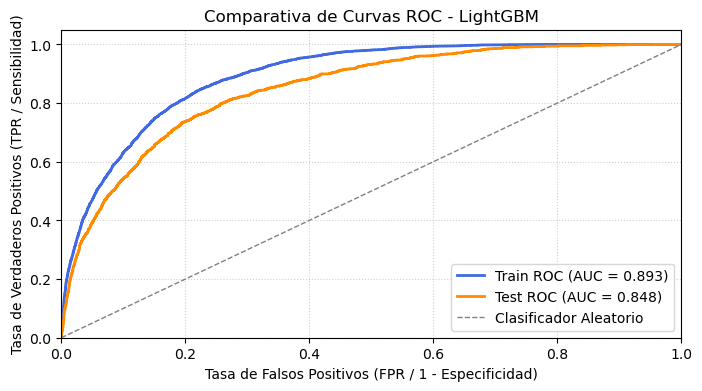

In [9]:
# Curva ROC

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# 1. Obtener las probabilidades de la clase positiva [:, 1] para Train y Test
y_proba_train = best_pipeline_lgb.predict_proba(X_train)[:, 1]
y_proba_test = best_pipeline_lgb.predict_proba(X_test)[:, 1]

# 2. Calcular el valor AUC para ambos conjuntos
auc_train = roc_auc_score(y_train, y_proba_train)
auc_test = roc_auc_score(y_test, y_proba_test)

# 3. Calcular las tasas FPR y TPR para generar las curvas
fpr_train, tpr_train, _ = roc_curve(y_train, y_proba_train)
fpr_test, tpr_test, _ = roc_curve(y_test, y_proba_test)

# 4. Graficar ambas curvas para comparar sobreajuste (Overfitting)
plt.figure(figsize=(8, 4))

# Línea del Train
plt.plot(fpr_train, tpr_train, color='royalblue', lw=2, 
         label=f'Train ROC (AUC = {auc_train:.3f})')

# Línea del Test
plt.plot(fpr_test, tpr_test, color='darkorange', lw=2, 
         label=f'Test ROC (AUC = {auc_test:.3f})')

# Línea de referencia aleatoria (diagonal)
plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--', label='Clasificador Aleatorio')

# Ajustes de formato del gráfico
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR / 1 - Especificidad)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR / Sensibilidad)')
plt.title('Comparativa de Curvas ROC - LightGBM')
plt.legend(loc="lower right")
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# BÚSQUEDA SEMÁNTICA

In [31]:
df_productos.groupby("brand").agg({"price": "max"}).sort_values(by="price", ascending=False).head(20)

,price
brand,
Road-150,3578.270000
Mountain-100,3399.990000
Road-250,407.225000
Touring-1000,397.345000
Mountain-200,386.665000
Road-350-W,283.498333
Road-450,242.998333
HL Road Frame,238.583333
HL Mountain Frame,227.416667


In [19]:
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer

# 1. Copia de trabajo
df_index = df_productos.copy()

# 2. Preparar texto para la búsqueda semántica
campos_texto = [
    "description",
    "subcategory",
    "brand",
    "category"
]

for col in campos_texto:
    df_index[col] = (
        df_index[col]
        .fillna("")
        .astype(str)
        .str.strip()
    )

df_index["search_text"] = (
    "Producto: " + df_index["description"]
    + ". Subcategoría: " + df_index["subcategory"]
    + ". Marca o modelo: " + df_index["brand"]
    + ". Categoría: " + df_index["category"]
)

# 3. Modelo multilingüe
model = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)

# 4. Indexación vectorial en memoria
embeddings = model.encode(
    df_index["search_text"].tolist(),
    normalize_embeddings=True,
    convert_to_numpy=True,
    show_progress_bar=True
)

# 5. Función de búsqueda
def buscar_productos(query, top_k=5, precio_max=None):
    query_vector = model.encode(
        [query],
        normalize_embeddings=True,
        convert_to_numpy=True
    )[0]

    # Similitud coseno: vectores normalizados
    scores = embeddings @ query_vector

    resultados = df_index.copy()
    resultados["similarity"] = scores

    # Filtro comercial opcional, separado de la similitud
    if precio_max is not None:
        resultados = resultados[
            pd.to_numeric(resultados["price"], errors="coerce")
            .le(precio_max)
        ]

    resultados = resultados.sort_values(
        "similarity", ascending=False
    ).head(top_k)

    return resultados[
        [
            "product_id",
            "description",
            "subcategory",
            "brand",
            "price",
            "similarity"
        ]
    ].reset_index(drop=True)

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

C:\Users\DELTA\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\DELTA\.cache\huggingface\hub\models--sentence-transformers--paraphrase-multilingual-MiniLM-L12-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 9.08MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

In [34]:
# Consulta semántica
query = (
    "Busco una bicicleta de alto rendimiento para "
    "ciclismo de carretera, de gama premium y "
    "orientada a ciclistas exigentes."
)

# Recuperar los 10 productos más similares
resultados = buscar_productos(query, top_k=5)

display(resultados)

,product_id,description,subcategory,brand,price,similarity
0,604,"Road-750 Black, 44",Road Bikes,Road-750,134.997500,0.672448
1,384,"Road-550-W Yellow, 40",Road Bikes,Road-550-W,186.748333,0.671678
2,383,"Road-550-W Yellow, 40",Road Bikes,Road-550-W,166.739583,0.671678
3,584,"Road-750 Black, 58",Road Bikes,Road-750,134.997500,0.671100
4,606,"Road-750 Black, 52",Road Bikes,Road-750,134.997500,0.668756


In [33]:
consultas = {
    "Gama premium": (
        "Busco una bicicleta de alto rendimiento, "
        "de gama premium para ciclistas exigentes."
    ),
    "Carretera": (
        "Necesito una bicicleta rápida para ciclismo "
        "de carretera y recorridos de larga distancia."
    ),
    "Montaña": (
        "Busco una bicicleta robusta para rutas de "
        "montaña y terrenos exigentes."
    )
}

for tipo, query in consultas.items():
    print(f"\n{'='*60}")
    print(f"Consulta: {tipo}")
    print(query)

    resultados = buscar_productos(query, top_k=5)
    display(resultados)


Consulta: Gama premium
Busco una bicicleta de alto rendimiento, de gama premium para ciclistas exigentes.


,product_id,description,subcategory,brand,price,similarity
0,597,"Mountain-500 Black, 42",Mountain Bikes,Mountain-500,134.9975,0.692885
1,598,"Mountain-500 Black, 44",Mountain Bikes,Mountain-500,134.9975,0.692126
2,600,"Mountain-500 Black, 52",Mountain Bikes,Mountain-500,134.9975,0.688752
3,596,"Mountain-500 Black, 40",Mountain Bikes,Mountain-500,134.9975,0.688407
4,599,"Mountain-500 Black, 48",Mountain Bikes,Mountain-500,134.9975,0.686472



Consulta: Carretera
Necesito una bicicleta rápida para ciclismo de carretera y recorridos de larga distancia.


,product_id,description,subcategory,brand,price,similarity
0,310,"Road-150 Red, 62",Road Bikes,Road-150,3578.270000,0.611126
1,311,"Road-150 Red, 44",Road Bikes,Road-150,3578.270000,0.609277
2,314,"Road-150 Red, 56",Road Bikes,Road-150,3578.270000,0.607915
3,384,"Road-550-W Yellow, 40",Road Bikes,Road-550-W,186.748333,0.607443
4,383,"Road-550-W Yellow, 40",Road Bikes,Road-550-W,166.739583,0.607443



Consulta: Montaña
Busco una bicicleta robusta para rutas de montaña y terrenos exigentes.


,product_id,description,subcategory,brand,price,similarity
0,597,"Mountain-500 Black, 42",Mountain Bikes,Mountain-500,134.9975,0.700555
1,599,"Mountain-500 Black, 48",Mountain Bikes,Mountain-500,134.9975,0.699589
2,598,"Mountain-500 Black, 44",Mountain Bikes,Mountain-500,134.9975,0.698656
3,596,"Mountain-500 Black, 40",Mountain Bikes,Mountain-500,134.9975,0.697544
4,600,"Mountain-500 Black, 52",Mountain Bikes,Mountain-500,134.9975,0.697443
